# Can the AML velocity graph resolve a fate for the disappearing blast compartment?

## Biological idea and study design

Treatment may reduce the abundance of an immature compartment without redirecting its differentiation. We therefore inspect the RNA-velocity field inferred from measured splicing counts, root affinity, discounted reach and coverage together, rather than treating a change in cell counts as a fate decision.

This workflow uses the genuine `Pollyea_merged.loom` splicing counts reconstructed by Ranek and colleagues ([Zenodo 6587903](https://doi.org/10.5281/zenodo.6587903)) and the original [GSE116481](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE116481) annotations. It compares baseline with day 2 after venetoclax plus azacitidine. Day 4 has only five annotated root cells and is shown in the source composition table rather than included in the primary fit.

**One patient is not a replicated treatment study.** The source label “Blasts and Immature Eryth” mixes biological identities, and malignant genotype is not available per cell. Monocytic and erythroid outcomes are annotation-defined states. This notebook demonstrates an end-to-end descriptive PairScorer analysis, not proof of malignant-blast differentiation or a causal treatment effect.

## Environment and reproducible settings

In [1]:
from pathlib import Path
import sys

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

In [2]:
from pathlib import Path
import sys
import importlib.metadata as metadata
import platform
import json

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
import scvelo as scv
import matplotlib
import matplotlib.pyplot as plt
from scipy import sparse
from IPython.display import display
import scCS
from benchmarks.validation.velocity_inputs import audit_counts, write_verified_loom

# Keep figures embedded in Jupyter and the exported documentation.
matplotlib.use("module://matplotlib_inline.backend_inline", force=True)

SEED = 19
np.random.seed(SEED)
DATA = PROJECT / "data" / "validation"
OUTPUT_DIR = PROJECT / "tutorial_outputs" / "aml_pair_velocity"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for package in ["scCS-py", "scanpy", "scvelo", "anndata"]:
    print(package, metadata.version(package))
plt.rcParams.update({"figure.dpi": 90, "figure.figsize": (7, 4)})

scCS-py 1.0.1.dev0
scanpy 1.12.6
scvelo 0.3.4
anndata 0.13.4


## 1. Load and audit real loom counts

The loader verifies the published loom checksum and joins annotations using **sample plus barcode**, because barcode sequences can recur at different time points. To keep loading practical, it reads only mapped cells and a reproducible count-variability gene screen, retaining prespecified marker genes. The source composition table is calculated before selecting the analysis compartment. No control/treated labels or transition perturbations are simulated.

In [3]:
from benchmarks.validation.data import load_aml, fetch

print("Original loom:", fetch("aml_loom", DATA))
raw = load_aml(DATA, n_genes=2000)
composition = pd.crosstab(raw.obs.cell_type, raw.obs["sample"])
display(composition)
composition.to_csv(OUTPUT_DIR / "source_composition.csv")
labels = {
    "Blasts and Immature Eryth": "Root",
    "Monocytes": "Monocytic",
    "Early Erythroids": "Erythroid",
    "Mature Erythroids": "Erythroid",
    "Macrophages": "Outside",
}
raw = raw[raw.obs.cell_type.isin(labels) & raw.obs["sample"].isin(["day0", "day2"])].copy()
raw.obs["source_state"] = raw.obs.cell_type.astype(str)
raw.obs["condition"] = raw.obs["sample"].astype(str)
raw.obs["clusters"] = raw.obs.cell_type.map(labels).astype(str)
display(audit_counts(raw))
display(pd.crosstab(raw.obs.source_state, raw.obs.condition))
print("Unique sample/barcode mapping:", raw.obs_names.is_unique)

Original loom: /workspace/scratch/1a48413c8396/replay/data/validation/Pollyea_merged.loom
Unique sample/barcode mapping: True


sample,day0,day2,day4
cell_type,,,
B-Cells (IgA),17,8,10
B-Cells (IgD),122,60,58
Blasts and Immature Eryth,654,146,5
CD4 T cells,395,111,162
CD8 T cells,581,257,286
Early Erythroids,29,8,0
Macrophages,13,5,3
Mature Erythroids,12,2,1
Megakaryocytes,36,5,10


,layer,cells,genes,total_counts,nonzero_entries
0,spliced,1186,2006,4225230.0,836827
1,unspliced,1186,2006,945405.0,367074


condition,day0,day2
source_state,,
Blasts and Immature Eryth,654,146
Early Erythroids,29,8
Macrophages,13,5
Mature Erythroids,12,2
Monocytes,212,105


**Which compartment shrinks?** In the joined annotations, blasts and immature erythroid cells together account for 654/2,365 cells at baseline (27.7%), 146/813 on day 2 (18.0%) and 5/790 on day 4 (0.6%). These are fractions of captured, annotated cells. Each time point samples different cells from the same patient.

## 2. Read the analysis loom and verify exact count identity

For a uniform loom-based workflow we export the selected **measured** counts, then verify that cell IDs, gene IDs and both layers survive the round trip exactly. The output loom is an analysis subset, not a new raw-read quantification. Existing mismatched count files raise an error rather than silently substituting different input. The generated file is local data and is not bundled into the package.

In [4]:
LOOM_PATH = DATA / "aml_day0_day2_counts_g2000.loom"
write_verified_loom(raw, LOOM_PATH)
adata = ad.read_loom(LOOM_PATH, obs_names="CellID", var_names="Gene", sparse=True)
display(audit_counts(adata))
print("Verified analysis loom:", LOOM_PATH)
del raw

Verified analysis loom: /workspace/scratch/1a48413c8396/replay/data/validation/aml_day0_day2_counts_g2000.loom


,layer,cells,genes,total_counts,nonzero_entries
0,spliced,1186,2006,4225230.0,836827
1,unspliced,1186,2006,945405.0,367074


## 3. Fit RNA velocity in expression space

The velocity estimator sees the measured spliced/unspliced layers and the native expression-neighbor graph. It never sees the scCS star coordinates. This tutorial runs the same dynamical scVelo workflow as the pancreas and Schwann PairScorer examples: `recover_dynamics(max_iter=20)`, dynamical velocity, velocity graph, inferred terminal states and latent time. Twenty iterations are a tutorial setting, not a convergence guarantee or a claim to reproduce a published Bayesian model. The model choice, count filtering, neighborhood and gene screen are assumptions to inspect before interpreting fate scores. A matching UMAP is recomputed for visualization only.

Filtered out 172 genes that are detected 10 counts (shared).
Normalized count data: X, spliced, unspliced.
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 1/9 cores)
    finished (0:01:17) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/9 cores)
    finished (0:00:00) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
--> added 'velocity_length' (adata.obs)
--> added 'velocity_confidence' (adata.obs)
--> added 'velocity_confidence_transition' (adata.obs)
computing terminal states
    identified 2 regions of root cells and 2 regions of end points .
    finished (0:00:00) --> added
    'root_cells', root cells of Markov diffusion process (adata.o

velocity_length           velocity_confidence          
                   median      mean              median      mean
condition                                                        
day0                7.075  8.374380            0.877947  0.870390
day2                8.130  8.652594            0.900383  0.883319

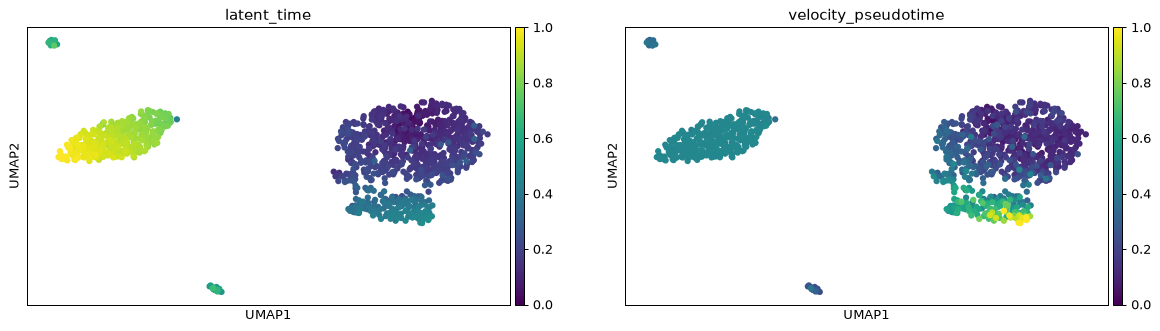

In [5]:
# Processing uses measured spliced/unspliced molecules, before any scCS display.
scv.pp.filter_genes(adata, min_shared_counts=10)
scv.pp.normalize_per_cell(adata)
sc.pp.log1p(adata)
sc.pp.pca(adata, n_comps=30, random_state=SEED)
sc.pp.neighbors(adata, n_neighbors=30, n_pcs=30, random_state=SEED)
sc.tl.umap(adata, random_state=SEED)
scv.pp.moments(adata, n_neighbors=None, n_pcs=None)
scv.tl.recover_dynamics(adata, max_iter=20, n_jobs=1, show_progress_bar=False)
scv.tl.velocity(adata, mode="dynamical")
scv.tl.velocity_graph(adata, n_jobs=1, show_progress_bar=False)
scv.tl.velocity_confidence(adata)
scv.tl.terminal_states(adata)
adata.obs["early_root_hint"] = (
    adata.obs.clusters.eq("Root")
    & adata.obs.condition.eq("day0" if "day0" in set(adata.obs.condition) else "day2")
).astype(float)
scv.tl.latent_time(adata, root_key="early_root_hint", end_key="end_points")
scv.tl.velocity_pseudotime(adata, root_key="early_root_hint")
print("Dynamically fitted genes:", int(adata.var.fit_likelihood.notna().sum()))
transition = scCS.get_scvelo_transition_matrix(adata)
adata.obsp["T_velocity"] = transition
print("Fitted velocity genes:", int(adata.var.velocity_genes.sum()))
display(
    adata.obs.groupby("condition", observed=True)[["velocity_length", "velocity_confidence"]].agg(
        ["median", "mean"]
    )
)
assert transition.shape == (adata.n_obs, adata.n_obs)
assert np.isfinite(transition.data).all()
sc.pl.umap(adata, color=["latent_time", "velocity_pseudotime"], show=False)
plt.show()

## 4. Inspect the native field and phase portraits

Arrows are estimated from the fitted RNA-velocity model. Smoothness in a stream plot and agreement among neighbors are diagnostics, not independent evidence of correct cell fate. The phase portraits use the two highest-likelihood dynamically fitted velocity genes; they are selected for fit inspection, not because their arrows support a desired treatment narrative. The displayed source annotations and sampled conditions let you assess overlap and gross inconsistencies.

computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)
Phase portraits selected by dynamical fit likelihood: [np.str_('NKG7'), np.str_('RPS4X')]


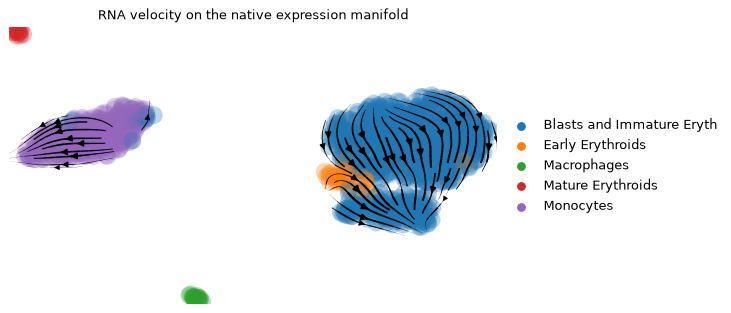

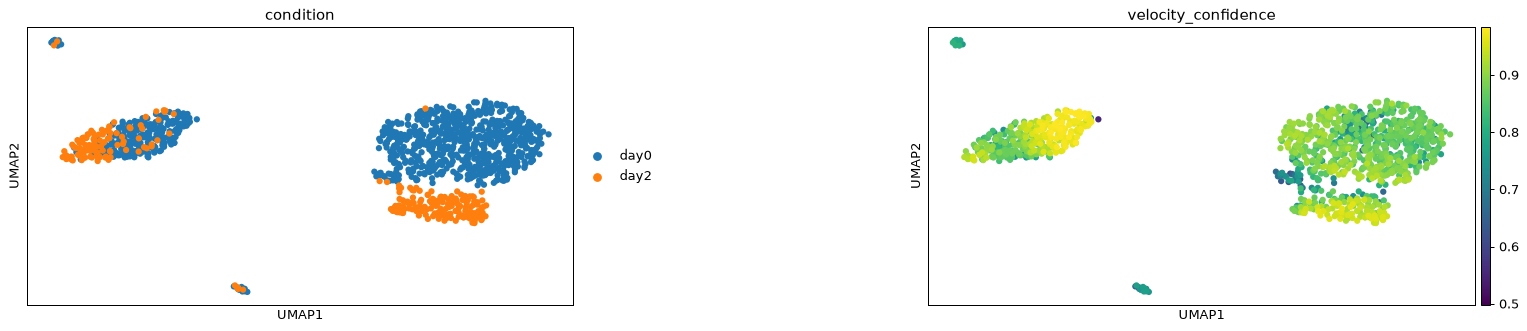

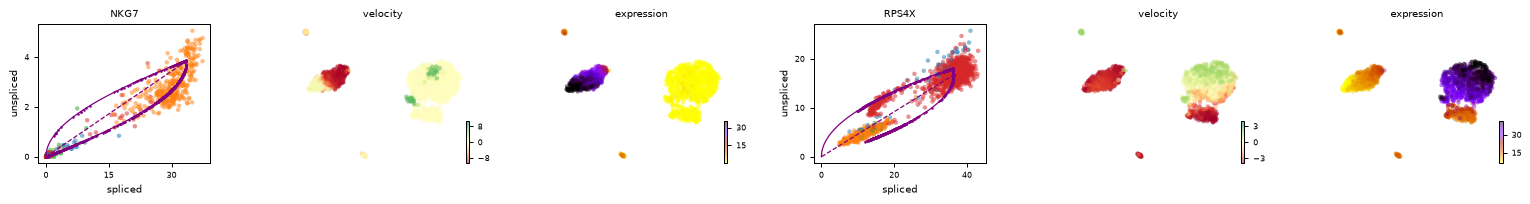

In [6]:
scv.pl.velocity_embedding_stream(
    adata,
    basis="umap",
    color="source_state",
    legend_loc="right margin",
    title="RNA velocity on the native expression manifold",
    show=False,
)
plt.show()
sc.pl.umap(adata, color=["condition", "velocity_confidence"], wspace=0.5, show=False)
plt.show()
phase_genes = (
    adata.var.loc[adata.var.velocity_genes]
    .sort_values("fit_likelihood", ascending=False)
    .head(2)
    .index.tolist()
)
print("Phase portraits selected by dynamical fit likelihood:", phase_genes)
if phase_genes:
    scv.pl.velocity(adata, var_names=phase_genes, ncols=2, show=False)
    plt.show()

## 5. Define the supervised question and ordering

The combined blast/immature-erythroid annotation is the root. Monocytes and erythroid cells define the selected outcomes; macrophages remain background graph context. A fixed mature-minus-immature marker score supplies the ordering, as in the initial AML pilot. It combines different maturation programs and must be checked against the displayed annotations. It is not an independent validation target, and it is not optimized to increase fate coverage.

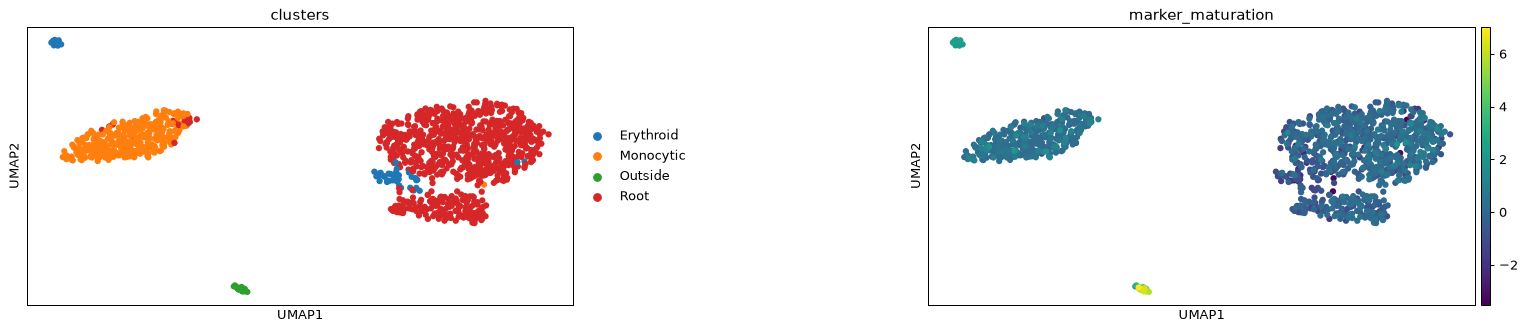

In [7]:
ROOT_LABEL = "Root"
FATES = ["Monocytic", "Erythroid"]
REPLICATE_KEY = "patient"
MARKER_GENES = ["CD34", "LYZ", "GATA1", "HBB"]


# A predefined expression proxy: it is not physical time or clonal ground truth.
def marker_score(genes):
    present = [gene for gene in genes if gene in adata.var_names]
    if not present:
        raise ValueError("Required maturation markers are absent.")
    x = adata[:, present].X
    x = x.toarray() if sparse.issparse(x) else np.asarray(x)
    return ((x - x.mean(0)) / (x.std(0) + 1e-8)).mean(1)


adata.obs["marker_maturation"] = marker_score(
    ["LYZ", "S100A8", "CTSS", "GATA1", "KLF1", "HBB"]
) - marker_score(["CD34", "KIT", "GATA2"])
ORDERING_KEY = "marker_maturation"
adata.obs["clusters"] = pd.Categorical(adata.obs.clusters)
sc.pl.umap(adata, color=["clusters", ORDERING_KEY], wspace=0.5, show=False)
plt.show()

**How to read the ordering.** The fitted gene panel contains LYZ, S100A8, CTSS and HBB from the maturation panel, and CD34, KIT and GATA2 from the immature panel. GATA1 and KLF1 did not survive the gene screen and filtering. The erythroid component of this particular ordering therefore relies on HBB. Early and mature erythroid annotations also share one fate label.

## 6. Preflight, shared geometry and PairScorer

The pooled fit uses one graph, ordering and anchor definition for both conditions. Background states remain in the native graph even though the supervised display contains the selected root and fates. `min_replicates=1` permits descriptive score summaries only; it does not authorize formal inference for the baseline and day-2 samples from one patient. The preflight replication errors are retained as such, while structural errors stop execution. Inspect the post-fit report for dead ends, unreachable outcomes and defined-affinity coverage.

In [8]:
pair = scCS.PairScorer(
    adata,
    root=ROOT_LABEL,
    branches=FATES,
    obs_key="clusters",
    condition_obs_key="condition",
    replicate_obs_key=REPLICATE_KEY,
    condition_order=["day0", "day2"] if REPLICATE_KEY == "patient" else ["day2", "day4"],
)
report = pair.preflight(ordering_metric=ORDERING_KEY, check_velocity=True)
report.display()
expected_design_errors = {f"condition_{condition}_replicates" for condition in pair.conditions}
unexpected = [d for d in report.errors if d.code not in expected_design_errors]
if unexpected:
    raise ValueError("Structural preflight failure: " + "; ".join(d.message for d in unexpected))
if report.errors:
    print("Replication errors remain: descriptive scoring only; formal inference is unavailable.")
pair.build_embedding(ordering_metric=ORDERING_KEY, cache_subset=False, verbose=False)
FUTURE_OPTIONS = {"effective_horizon": 64, "anchor_quantile": 0.9, "min_anchor_cells": 3}
pair.fit(
    transition_matrix=transition,
    scoring_mode="future_fate",
    transition_scope="pooled",
    future_fate_options=FUTURE_OPTIONS,
    verbose=False,
)
results = pair.score_all_conditions(
    population="root", min_cells=5, min_replicates=1, write_to_adata=False, verbose=False
)
postflight = pair.preflight(ordering_metric=ORDERING_KEY, check_velocity=True)
postflight.display()
unexpected = [d for d in postflight.errors if d.code not in expected_design_errors]
if unexpected:
    raise ValueError("Post-fit structural failure: " + "; ".join(d.message for d in unexpected))
postflight.to_frame().to_csv(OUTPUT_DIR / "preflight.csv", index=False)

Replication errors remain: descriptive scoring only; formal inference is unavailable.


,level,code,message,value
0,info,furcation_valid,Root and terminal annotations are valid.,1168
1,info,root_cells,Root population contains 800 cells.,800
2,info,terminal_Monocytic,Terminal 'Monocytic' contains 317 cells.,317
3,info,terminal_Erythroid,Terminal 'Erythroid' contains 51 cells.,51
4,info,ordering_valid,Ordering metric is finite and non-constant amo...,1.0
5,info,ordering_resolution,Root ordering has 640 unique values across 800...,0.8
6,info,velocity_available,Velocity information is available.,None
7,info,condition_day0_cells,Condition 'day0' contains 920 cells.,920
8,info,condition_day2_cells,Condition 'day2' contains 266 cells.,266
9,info,replicate_labels_reused,Some raw replicate labels occur in multiple co...,[patient_1]


,level,code,message,value
0,info,furcation_valid,Root and terminal annotations are valid.,1168
1,info,root_cells,Root population contains 800 cells.,800
2,info,terminal_Monocytic,Terminal 'Monocytic' contains 317 cells.,317
3,info,terminal_Erythroid,Terminal 'Erythroid' contains 51 cells.,51
4,info,ordering_valid,Ordering metric is finite and non-constant amo...,1.0
5,info,ordering_resolution,Root ordering has 640 unique values across 800...,0.8
6,info,velocity_available,Velocity information is available.,None
7,info,graph_dead_end_nonanchors,0 selected non-anchor cells have no positive o...,0
8,warning,root_unreachable_selected_anchors,776 root cells have no graph path to selected ...,776
9,info,transition_coverage,"Root transition coverage median=1.000, q05=1.000.",1.0


## 7. Read conditional affinity together with reach and coverage

Conditional fate affinity (CFA) is the share of discounted reach assigned to a fate. The table averages CFA over roots with combined reach of at least 10⁻⁶. Discounted fate reach (DFR) and unresolved fate probability (UFP) average across every root cell in the condition. These denominators answer different questions: DFR is a mean discounted probability, not the fraction of cells that will differentiate. No undefined CFA is replaced by zero. The table prints both the numerator and denominator for defined-affinity coverage, so a high conditional CFA cannot conceal a mostly unresolved population.

,condition,n_root_cells,n_defined_CFA,defined_fraction,DFR,UFP,SOF,CFA_Monocytic,CFA_Erythroid
0,day0,654,22,0.033639,0.019141,0.980859,-0.017841,1.0,0.0
1,day2,146,2,0.013699,0.010728,0.989272,0.054589,1.0,0.0


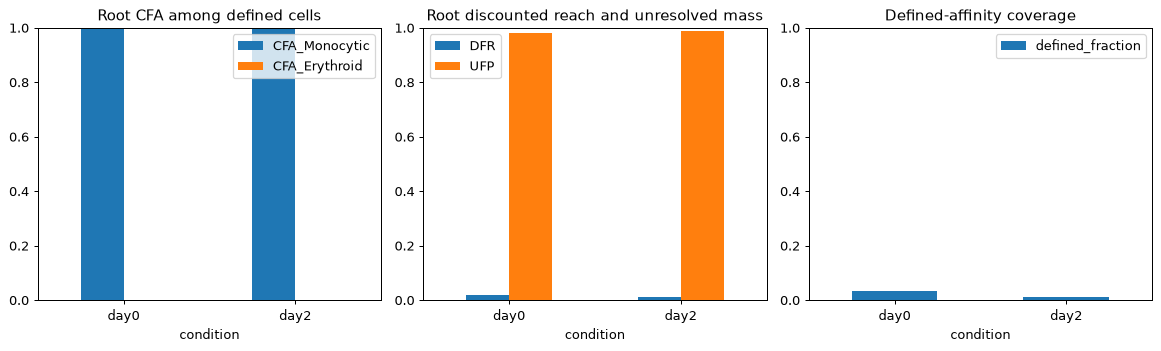

In [9]:
pooled = pair.result
rows = []
for condition, result in results.items():
    locations = pd.Index(pooled.cell_ids).get_indexer(result.cell_ids)
    assert (locations >= 0).all()
    defined = pooled.affinity_defined[locations]
    row = {
        "condition": condition,
        "n_root_cells": len(locations),
        "n_defined_CFA": int(defined.sum()),
        "defined_fraction": float(defined.mean()),
        "DFR": float(pooled.discounted_fate_reach[locations].mean()),
        "UFP": float(pooled.unresolved_probability[locations].mean()),
        "SOF": float(pooled.signed_progression[locations].mean()),
    }
    for j, fate in enumerate(pooled.fate_names):
        row["CFA_" + fate] = (
            float(pooled.conditional_fate_affinity[locations[defined], j].mean())
            if defined.any()
            else np.nan
        )
    rows.append(row)
summary = pd.DataFrame(rows)
display(summary)
summary.to_csv(OUTPUT_DIR / "condition_summary.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
summary.set_index("condition")[["CFA_" + f for f in FATES]].plot.bar(ax=axes[0], ylim=(0, 1))
summary.set_index("condition")[["DFR", "UFP"]].plot.bar(ax=axes[1], ylim=(0, 1))
summary.set_index("condition")[["defined_fraction"]].plot.bar(ax=axes[2], ylim=(0, 1))
axes[0].set_title("Root CFA among defined cells")
axes[1].set_title("Root discounted reach and unresolved mass")
axes[2].set_title("Defined-affinity coverage")
for axis in axes:
    axis.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()

**Why the monocytic bars both reach 1.** Only 22/654 baseline roots and 2/146 day-2 roots have defined CFA. A directed-path check on the fitted graph finds that 0 baseline roots and 0 day-2 roots can reach a late erythroid anchor before another outcome. Monocytic CFA therefore reaches 1 among the few roots connected to the selected endpoints. Averaged over **all** roots, discounted reach is only 0.019 and 0.011.

## 8. Compare conditions on the same star

These are shared-geometry displays of the native-graph results. Refitting dynamics in the star would change the model and is not performed. Inspect population identity, each fate's CFA, selected-fate reach, unresolved probability and Signed Ordering Flux (SOF). SOF describes movement relative to the chosen ordering; it is not an independent measurement of chronological maturation.

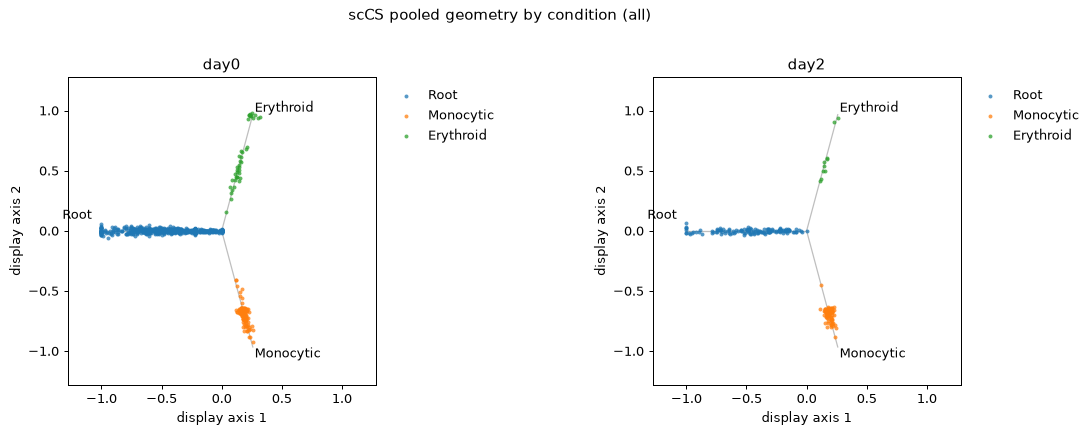

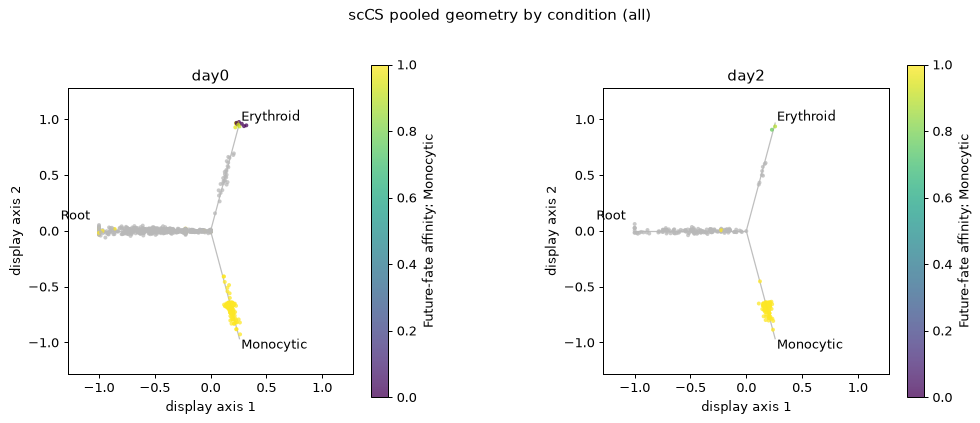

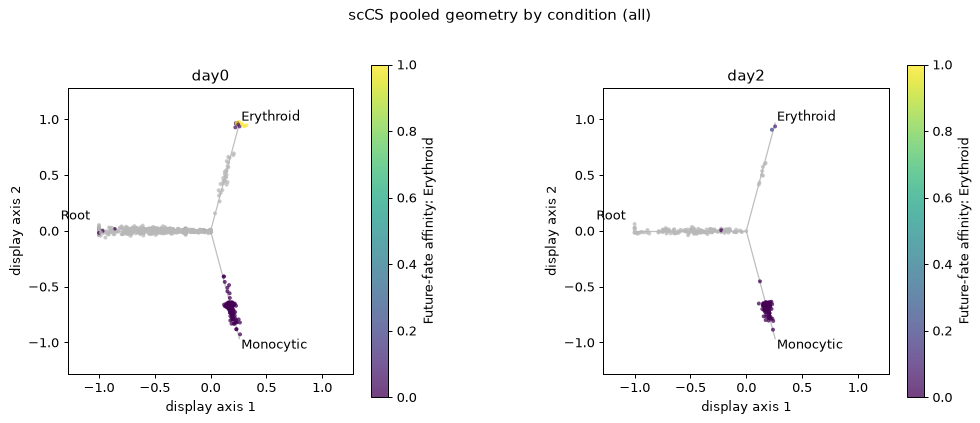

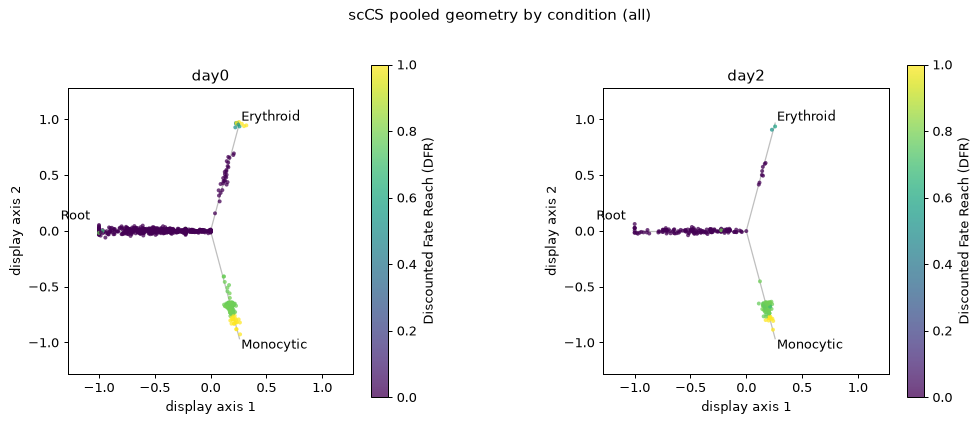

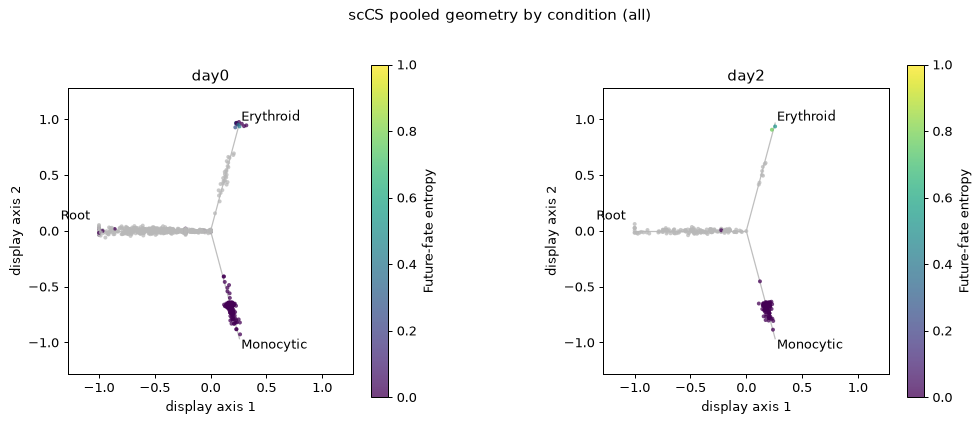

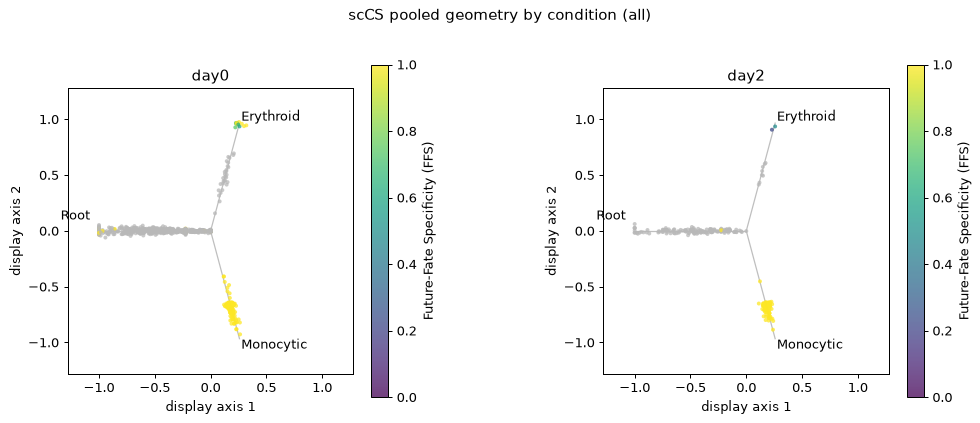

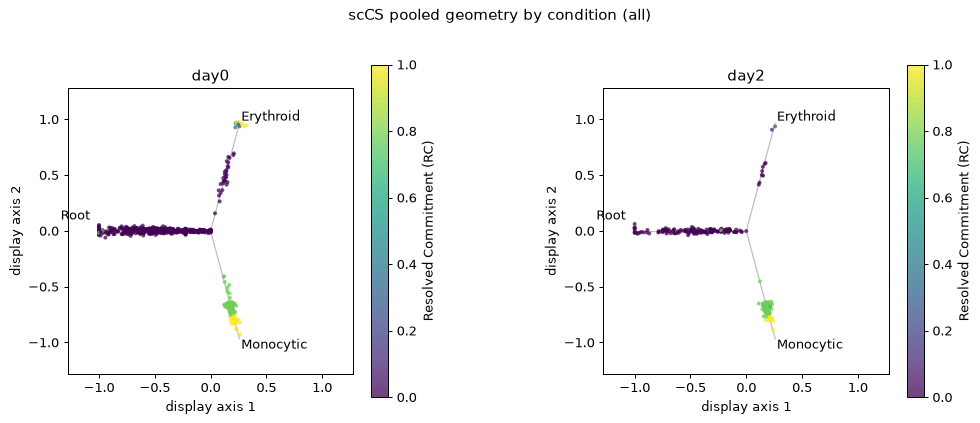

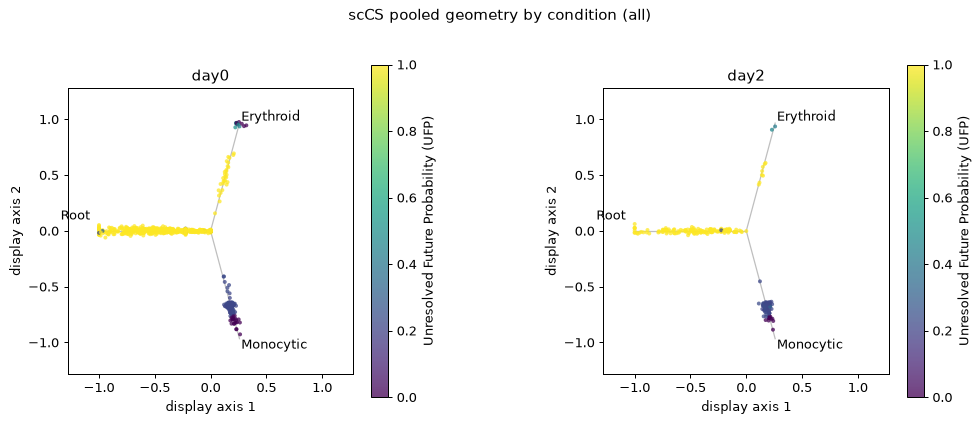

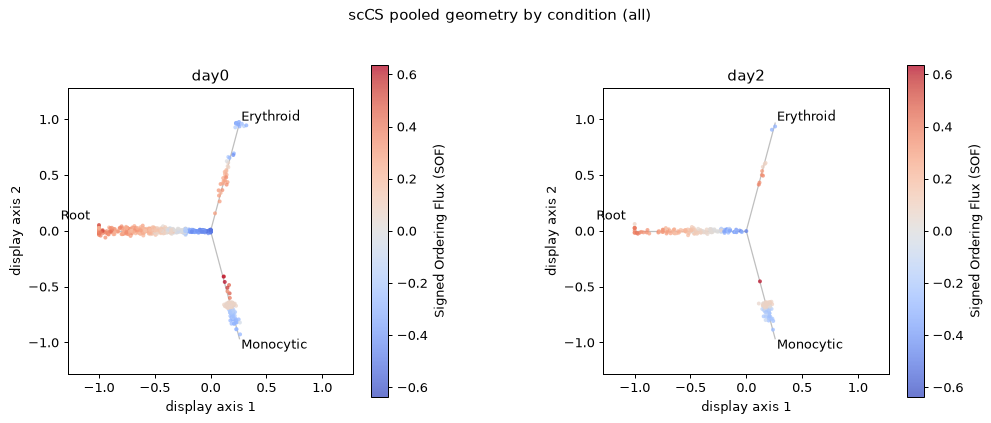

In [10]:
star_metrics = [
    "population",
    *["future_fate_affinity:" + f for f in FATES],
    "future_fate_reach",
    "future_fate_entropy",
    "future_fate_specificity",
    "reach_supported_specificity",
    "unresolved_future_probability",
    "signed_progression",
]
for color_by in star_metrics:
    figure = pair.plot_star_grid(
        results, color_by=color_by, population="all", ncols=2, figsize_per_panel=(6.4, 4.8)
    )
    if color_by == "population":
        figure.subplots_adjust(wspace=0.9)
    plt.show()

## 9. Inspect status, transition coverage and expression

Status and mean root graph-coverage plots help distinguish missing information from a conditional preference. The coverage bars have no replicate confidence intervals. Marker expression is shown from the normalized, log-transformed `X` matrix on a shared color scale. These panels are descriptive checks rather than differential-expression tests or proof that a root cell produced a particular descendant.

Markers absent after count filtering: ['GATA1']


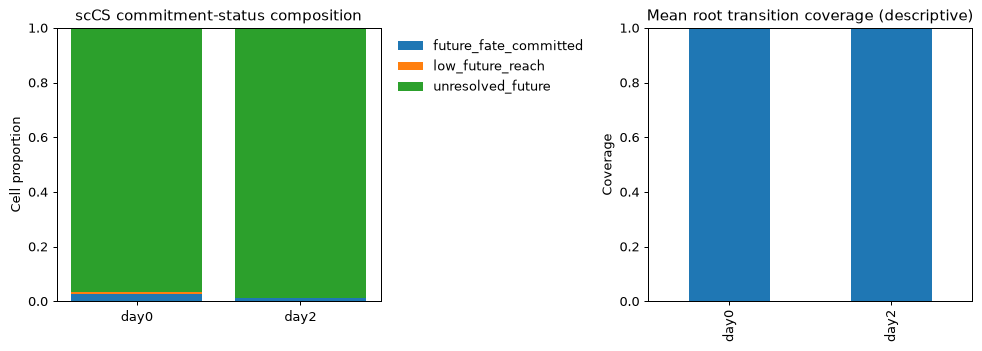

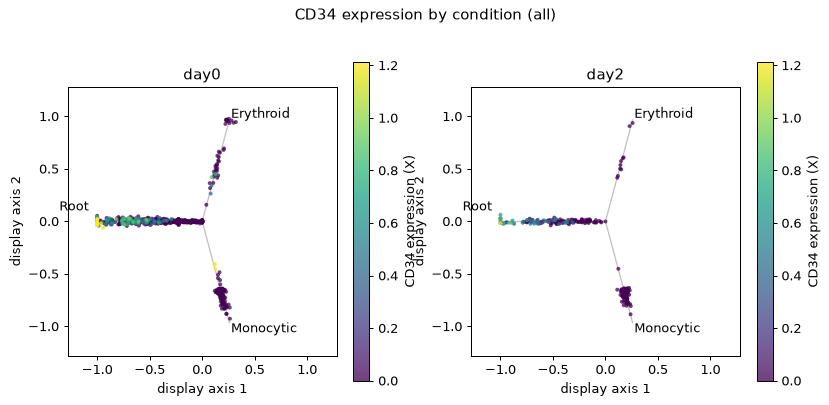

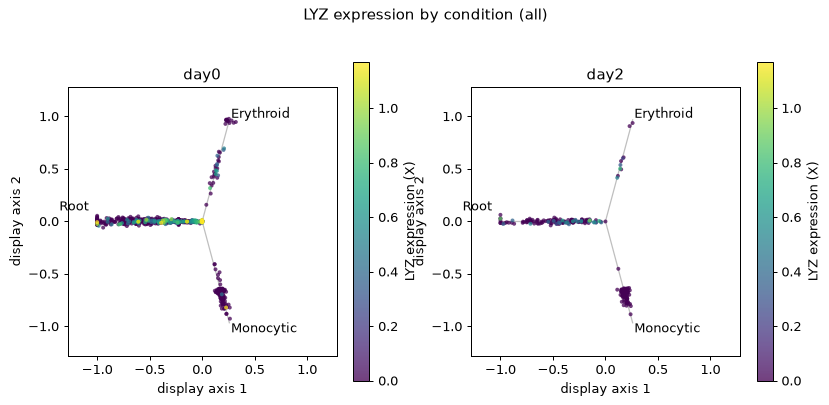

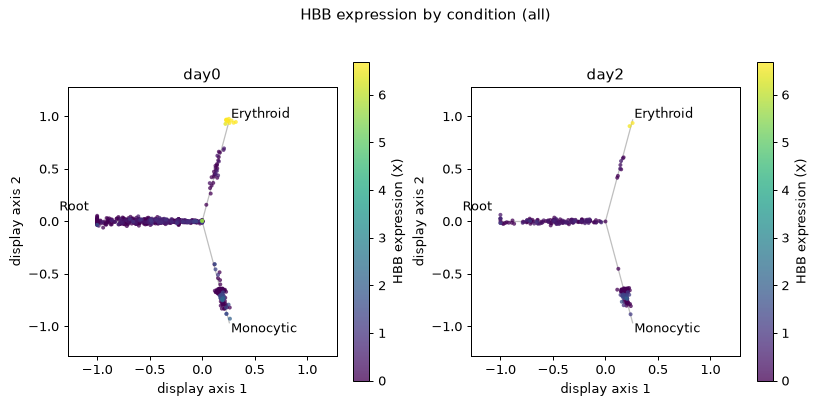

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
pair.plot_status_composition(results, ax=axes[0])
coverage_means = pd.Series(
    {name: np.mean(value.transition_coverage) for name, value in results.items()}
)
coverage_means.plot.bar(ax=axes[1], ylim=(0, 1))
axes[1].set_title("Mean root transition coverage (descriptive)")
axes[1].set_ylabel("Coverage")
fig.tight_layout()
plt.show()
print(
    "Markers absent after count filtering:", [g for g in MARKER_GENES if g not in adata.var_names]
)
for gene in MARKER_GENES:
    if gene in adata.var_names:
        pair.plot_gene_expression_star_grid(
            gene, results, shared_scale=True, ncols=2, figsize_per_panel=(5.3, 4.6)
        )
        plt.show()

## 10. Sensitivity to borrowing between conditions

The pooled graph can borrow neighbors across conditions. Blocking cross-condition transitions tests a different graph assumption while retaining the same velocity fit and supervised outcome definition. It does not refit scVelo independently in each condition. Lower reach after blocking can result from lost graph connections; it is not automatically evidence for biological arrest.

In [12]:
scope_rows = []
for scope in ["pooled", "condition"]:
    sensitivity = scCS.PairScorer(
        adata,
        root=ROOT_LABEL,
        branches=FATES,
        obs_key="clusters",
        condition_obs_key="condition",
        replicate_obs_key=REPLICATE_KEY,
        condition_order=list(results),
    )
    sensitivity.build_embedding(ordering_metric=ORDERING_KEY, cache_subset=False, verbose=False)
    sensitivity.fit(
        transition_matrix=transition,
        scoring_mode="future_fate",
        transition_scope=scope,
        future_fate_options=FUTURE_OPTIONS,
        verbose=False,
    )
    condition_results = sensitivity.score_all_conditions(
        population="root", min_cells=5, min_replicates=1, write_to_adata=False, verbose=False
    )
    for condition, result in condition_results.items():
        scope_rows.append(
            {
                "scope": scope,
                "condition": condition,
                "DFR": float(np.mean(result.commitment_strength)),
                "UFP": float(np.mean(result.unresolved_probability)),
                "defined_fraction": float(np.mean(result.affinity_defined)),
            }
        )
scope_summary = pd.DataFrame(scope_rows)
display(scope_summary)
scope_summary.to_csv(OUTPUT_DIR / "transition_scope_sensitivity.csv", index=False)

,scope,condition,DFR,UFP,defined_fraction
0,pooled,day0,0.019141,0.980859,0.033639
1,pooled,day2,0.010728,0.989272,0.013699
2,condition,day0,0.019676,0.980324,0.033639
3,condition,day2,0.010502,0.989498,0.013699


**What blocking changes.** Baseline supplies 6 of the 6 late erythroid anchors. Day 2 supplies 11 late monocytic anchors. Restricting transitions to the same day leaves 22 and 2 roots with defined CFA. Pooling alone cannot explain the low coverage.

## Complete scalar and fate-wise outcome tables

Each row below is a root cell, and each summary explicitly counts finite values. Conditional affinity, entropy and specificity remain undefined when the selected fates cannot be reached. Means across cells describe this observed sample; they are not biological-replicate estimates or confidence intervals. The exported cell table makes the denominators inspectable.

In [13]:
cell_tables = []
for condition, result in results.items():
    table = pd.DataFrame(
        {
            "condition": condition,
            "cell_id": result.cell_ids,
            "ordering": adata.obs.loc[result.cell_ids, ORDERING_KEY].to_numpy(),
            "DFR": result.commitment_strength,
            "UFP": result.unresolved_probability,
            "conditional_entropy": result.directional_entropy,
            "conditional_specificity": result.directional_specificity,
            "reach_supported_specificity": result.specific_commitment,
            "SOF": result.progression_velocity,
            "path_coverage": result.transition_coverage,
        }
    )
    for j, fate in enumerate(FATES):
        table["CFA_" + fate] = result.directional_affinity[:, j]
        table["contribution_" + fate] = result.commitment_contribution[:, j]
    cell_tables.append(table)
cell_table = pd.concat(cell_tables, ignore_index=True)
metric_columns = [c for c in cell_table if c not in ["condition", "cell_id", "ordering"]]
outcomes = cell_table.groupby("condition", observed=True)[metric_columns].agg(["mean", "count"])
with pd.option_context("display.max_columns", None, "display.width", 180):
    display(outcomes.T)
cell_table.to_csv(OUTPUT_DIR / "root_cell_outcomes.csv", index=False)
outcomes.to_csv(OUTPUT_DIR / "complete_outcome_summary.csv")

condition                                  day0          day2
DFR                         mean   1.914137e-02  1.072849e-02
                            count  6.540000e+02  1.460000e+02
UFP                         mean   9.808586e-01  9.892715e-01
                            count  6.540000e+02  1.460000e+02
conditional_entropy         mean   4.982892e-14  4.982892e-14
                            count  2.200000e+01  2.000000e+00
conditional_specificity     mean   1.000000e+00  1.000000e+00
                            count  2.200000e+01  2.000000e+00
reach_supported_specificity mean   1.914137e-02  1.072849e-02
                            count  6.540000e+02  1.460000e+02
SOF                         mean  -1.784082e-02  5.458894e-02
                            count  6.540000e+02  1.460000e+02
path_coverage               mean   9.997137e-01  1.000000e+00
                            count  6.540000e+02  1.460000e+02
CFA_Monocytic               mean   1.000000e+00  1.000000e+00
                            count  2.200000e+01  2.000000e+00
contribution_Monocytic      mean   1.914137e-02  1.072849e-02
                            count  6.540000e+02  1.460000e+02
CFA_Erythroid               mean   0.000000e+00  0.000000e+00
                            count  2.200000e+01  2.000000e+00
contribution_Erythroid      mean   0.000000e+00  0.000000e+00
                            count  6.540000e+02  1.460000e+02

## How much did the scores change?

The contrast is **day2 minus day0**. DFR measures discounted access to either destination. Each endpoint contribution averages over all roots, including roots with zero reach. CFA averages over defined roots. Read its denominator alongside the change. Each cell has equal weight within its group. The values describe the sampled roots.

,roots,defined roots
condition,,
day0,654,22
day2,146,2


condition,day0,day2,change
DFR,0.0191,0.0107,-0.0084
UFP,0.9809,0.9893,0.0084
defined fraction,0.0336,0.0137,-0.0199
contribution_Monocytic,0.0191,0.0107,-0.0084
contribution_Erythroid,0.0000,0.0000,0.0000
CFA_Monocytic,1.0000,1.0000,0.0000
CFA_Erythroid,0.0000,0.0000,0.0000


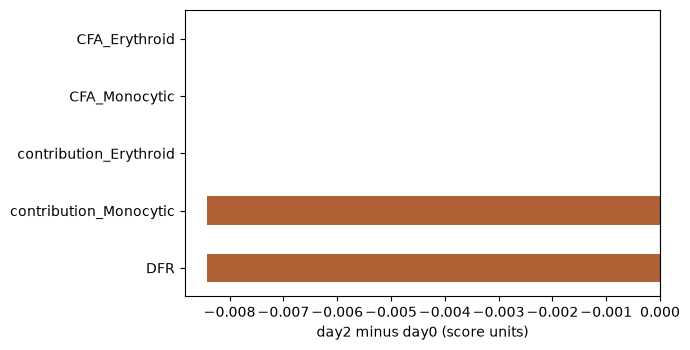

In [20]:
comp = cell_table.copy()
arms = ['day0', 'day2']
affinities = ['CFA_Monocytic', 'CFA_Erythroid']
contributions = ['contribution_Monocytic', 'contribution_Erythroid']
comp["defined fraction"] = comp[affinities].notna().all(axis=1)
metrics = ["DFR", "UFP", "defined fraction"] + contributions + affinities
arm = comp.groupby("condition", observed=True)[metrics].mean().reindex(arms)
effect = arm.T.copy()
effect["change"] = effect[arms[1]] - effect[arms[0]]
counts = comp.groupby("condition", observed=True)["defined fraction"].agg(["size","sum"]).reindex(arms)
display(counts.rename(columns={"size":"roots","sum":"defined roots"}))
display(effect.round(4))
np.testing.assert_allclose(effect.loc[contributions,"change"].sum(),effect.loc["DFR","change"],atol=1e-9)
effect.to_csv(OUTPUT_DIR / "condition_contrast.csv")
panel = effect.loc[["DFR"] + contributions + affinities,"change"]
ax = panel.plot.barh(figsize=(7,3.6),color=np.where(panel>=0,"#287867","#af6035"))
ax.axvline(0,color="black",lw=.8)
ax.set_xlabel(arms[1] + " minus " + arms[0] + " (score units)")
plt.tight_layout()
plt.show()

Mean DFR changed by **-0.0084**. The decrease in reach accompanies very low defined-affinity coverage on both days. The conditional monocytic affinity of 1.0 describes only 22 baseline roots and two day-2 roots in this patient.

## Condition summaries, composition and trajectory shifts

The contribution bar chart and heatmaps display sample means, with no cell-resampling error bars. The radar normalizes the mean fate contributions and therefore summarizes reach-weighted composition; it need not equal mean CFA. The SOF histogram describes cell-level movement relative to the specified ordering, not a test of developmental progression between independent experiments.

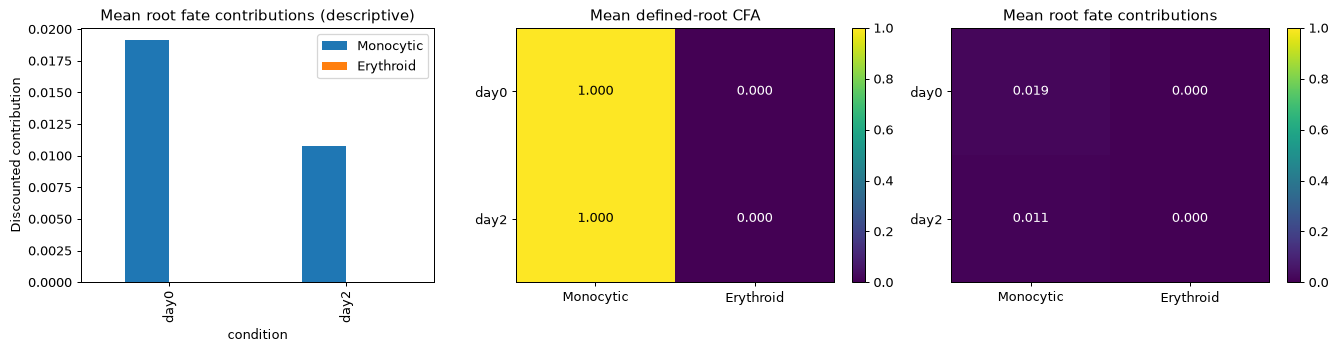

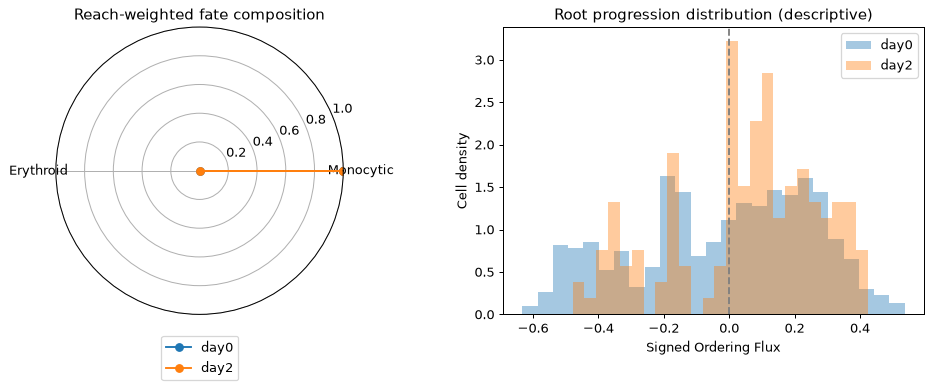

In [14]:
means = cell_table.groupby("condition", observed=True)[metric_columns].mean().reindex(results)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
means[["contribution_" + f for f in FATES]].rename(
    columns={"contribution_" + f: f for f in FATES}
).plot.bar(ax=axes[0])
axes[0].set_title("Mean root fate contributions (descriptive)")
axes[0].set_ylabel("Discounted contribution")
for axis, columns, title in [
    (axes[1], ["CFA_" + f for f in FATES], "Mean defined-root CFA"),
    (axes[2], ["contribution_" + f for f in FATES], "Mean root fate contributions"),
]:
    values = means[columns].to_numpy()
    image = axis.imshow(values, vmin=0, vmax=1, cmap="viridis", aspect="auto")
    axis.set(
        xticks=np.arange(len(FATES)),
        xticklabels=FATES,
        yticks=np.arange(len(means)),
        yticklabels=means.index,
        title=title,
    )
    for row in range(len(means)):
        for column in range(len(FATES)):
            value = values[row, column]
            axis.text(
                column,
                row,
                f"{value:.3f}" if np.isfinite(value) else "undefined",
                ha="center",
                va="center",
                color="white" if value < 0.5 else "black",
            )
    fig.colorbar(image, ax=axis, fraction=0.05)
fig.tight_layout()
plt.show()

fig = plt.figure(figsize=(11, 4.5))
radar = fig.add_subplot(121, projection="polar")
hist = fig.add_subplot(122)
angles = np.linspace(0, 2 * np.pi, len(FATES), endpoint=False)
for condition in results:
    values = means.loc[condition, ["contribution_" + f for f in FATES]].to_numpy(float)
    if values.sum() > 0:
        values /= values.sum()
        radar.plot(np.r_[angles, angles[0]], np.r_[values, values[0]], marker="o", label=condition)
    values = cell_table.loc[cell_table.condition.eq(condition), "SOF"]
    hist.hist(values[np.isfinite(values)], bins=25, density=True, alpha=0.4, label=condition)
radar.set_xticks(angles, FATES)
radar.set_ylim(0, 1)
radar.set_title("Reach-weighted fate composition")
radar.legend(loc="lower center", bbox_to_anchor=(0.5, -0.25))
hist.axvline(0, color="0.5", linestyle="--")
hist.set(
    xlabel="Signed Ordering Flux",
    ylabel="Cell density",
    title="Root progression distribution (descriptive)",
)
hist.legend()
fig.tight_layout()
plt.show()

## Ordering trends with observed-cell denominators

Common ordering bins are used across both conditions. The curves below summarize observed root cells, and the accompanying table records the number of finite values in each bin. They have no biological-replicate confidence bands. This explicit descriptive calculation is used instead of calling the replicate-aware trend API with invented replicate IDs.

ordering       CFA_Monocytic             DFR  \
                                mean count          mean count      mean   
condition ordering_bin                                                     
day0      (-3.488, -0.963] -1.520097    82           1.0     6  0.018816   
          (-0.963, -0.643] -0.789563    77           NaN     0  0.000000   
          (-0.643, -0.372] -0.496020    81           NaN     0  0.000000   
          (-0.372, -0.108] -0.229549    78           NaN     0  0.000000   
          (-0.108, 0.182]   0.132982   207           1.0    12  0.040074   
          (0.182, 0.387]    0.316753    38           NaN     0  0.000000   
          (0.387, 1.765]    0.700628    91           1.0     4  0.029453   
day2      (-3.488, -0.963] -1.596586    18           NaN     0  0.000000   
          (-0.963, -0.643] -0.825403    23           NaN     0  0.000000   
          (-0.643, -0.372] -0.463334    19           NaN     0  0.000000   
          (-0.372, -0.108] -0.261835    22           NaN     0  0.000000   
          (-0.108, 0.182]   0.076354    39           1.0     2  0.040163   
          (0.182, 0.387]    0.303269    16           NaN     0  0.000000   
          (0.387, 1.765]    0.525834     9           NaN     0  0.000000   

                                       SOF        
                           count      mean count  
condition ordering_bin                            
day0      (-3.488, -0.963]    82  0.343104    82  
          (-0.963, -0.643]    77  0.248099    77  
          (-0.643, -0.372]    81  0.170545    81  
          (-0.372, -0.108]    78  0.068283    78  
          (-0.108, 0.182]    207 -0.108846   207  
          (0.182, 0.387]      38 -0.387174    38  
          (0.387, 1.765]      91 -0.448378    91  
day2      (-3.488, -0.963]    18  0.346625    18  
          (-0.963, -0.643]    23  0.253845    23  
          (-0.643, -0.372]    19  0.164017    19  
          (-0.372, -0.108]    22  0.094595    22  
          (-0.108, 0.182]     39 -0.031100    39  
          (0.182, 0.387]      16 -0.299526    16  
          (0.387, 1.765]       9 -0.366646     9

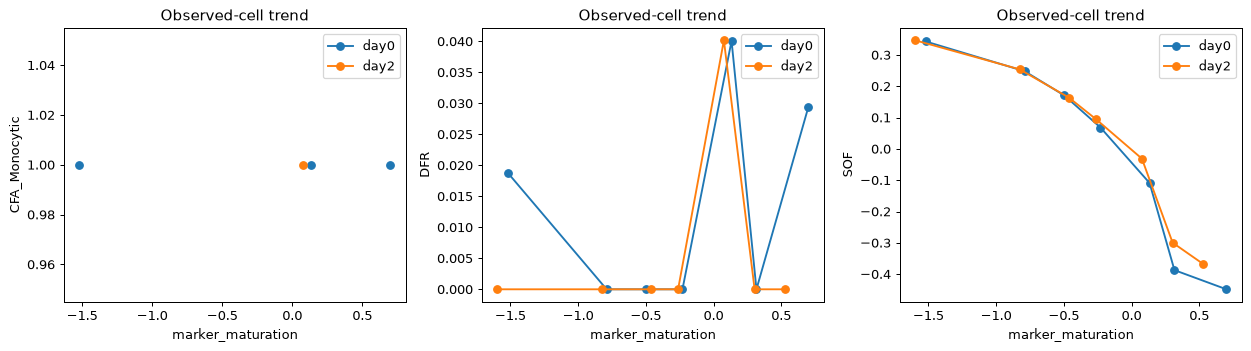

In [15]:
edges = np.unique(np.quantile(cell_table.ordering, np.linspace(0, 1, 9)))
if len(edges) < 4:
    raise ValueError("The root ordering has too few distinct values for trend plots.")
cell_table["ordering_bin"] = pd.cut(cell_table.ordering, bins=edges, include_lowest=True)
trend_columns = ["ordering", "CFA_" + FATES[0], "DFR", "SOF"]
trends = cell_table.groupby(["condition", "ordering_bin"], observed=True)[trend_columns].agg(
    ["mean", "count"]
)
with pd.option_context("display.max_rows", 40, "display.max_columns", None):
    display(trends)
trends.to_csv(OUTPUT_DIR / "descriptive_ordering_trends.csv")
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for condition in results:
    curve = trends.loc[condition]
    for axis, metric in zip(axes, ["CFA_" + FATES[0], "DFR", "SOF"]):
        axis.plot(curve[("ordering", "mean")], curve[(metric, "mean")], marker="o", label=condition)
        axis.set(xlabel=ORDERING_KEY, ylabel=metric, title="Observed-cell trend")
for axis in axes:
    axis.legend()
fig.tight_layout()
plt.show()

## Instantaneous velocity roses, fitted independently from DFFP

As in the other PairScorer tutorials, the root roses summarize instantaneous fate-directed velocity after accounting for incoming-root progression. They are a display diagnostic rather than discounted future-fate probabilities. A separate pooled instantaneous scorer protects the primary DFFP result from being overwritten.

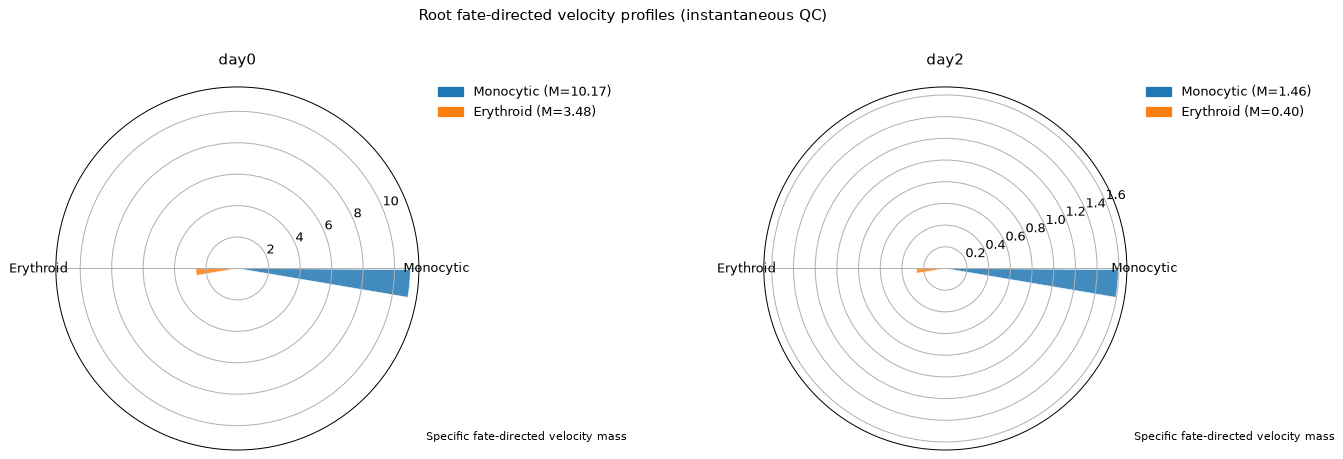

In [16]:
display_pair = scCS.PairScorer(
    adata,
    root=ROOT_LABEL,
    branches=FATES,
    obs_key="clusters",
    condition_obs_key="condition",
    replicate_obs_key=REPLICATE_KEY,
    condition_order=list(results),
)
display_pair.build_embedding(ordering_metric=ORDERING_KEY, cache_subset=False, verbose=False)
display_pair.fit(
    transition_matrix=transition,
    scoring_mode="instantaneous",
    transition_scope="pooled",
    verbose=False,
)
display_results = display_pair.score_all_conditions(
    population="root", min_cells=1, min_replicates=1, write_to_adata=False, verbose=False
)
rose_figure = display_pair.plot_rose_grid(
    display_results,
    population="root",
    mode="branch",
    n_bins=36,
    ncols=2,
    title="Root fate-directed velocity profiles (instantaneous QC)",
)
rose_figure.set_size_inches(14, 5.5)
rose_figure.subplots_adjust(wspace=0.95, left=0.05, right=0.9)
plt.show()

## 11. Respect the experimental unit

The source metadata are retained without inventing donors from cells, library batches, time points or clone barcodes. A formal PairScorer comparison is attempted below to show that the unsupported design is rejected. The appropriate output here is descriptive scores with explicit coverage. Independent biological replication, and an analysis that respects any pairing, would be required for population-level treatment inference.

In [17]:
# Requesting a formal test must fail rather than use cells as independent replicates.
try:
    pair.compare_conditions(results, metric="future_fate_reach", verbose=False)
except ValueError as error:
    print("Formal inference is unavailable for this design:", error)
    inference_refused = True
else:
    raise AssertionError("This descriptive design must not produce a treatment p-value.")
inference_audit = pd.DataFrame(
    [
        {
            "analysis": name,
            "status": "not estimable for this experimental design",
            "reason": "one patient per condition"
            if REPLICATE_KEY
            else "no independent-replicate metadata",
        }
        for name in [
            "replicate permutation test",
            "biological-replicate bootstrap",
            "replicate mixed model",
        ]
    ]
)
display(inference_audit)
inference_audit.to_csv(OUTPUT_DIR / "inference_availability.csv", index=False)

Formal inference is unavailable for this design: At least two defined biological replicates per condition are required; included counts={'day0': 1, 'day2': 1}, requested counts={'day0': 1, 'day2': 1}; excluded replicates=[].


,analysis,status,reason
0,replicate permutation test,not estimable for this experimental design,one patient per condition
1,biological-replicate bootstrap,not estimable for this experimental design,one patient per condition
2,replicate mixed model,not estimable for this experimental design,one patient per condition


## 12. Export and interpretation

The analysis object stores the actual splicing layers after normalization, fitted velocity vectors, native neighbor graph, UMAP, ordering and scCS scores. The source count files and checksums remain the reference for raw molecules. CSV exports record the condition summaries, graph-scope sensitivity and velocity diagnostics. Figures are retained in this executed notebook for Read the Docs.

Dynamical velocity is undefined for some unfitted genes. The final checks validate the selected velocity genes and the transition graph; undefined values outside that set are retained rather than replaced with artificial velocities.

In [18]:
pair.result.write_to_adata(adata)
adata.write_h5ad(OUTPUT_DIR / "pair_scorer_velocity_analysis.h5ad", compression="gzip")
adata.obs[
    ["condition", "source_state", "velocity_length", "velocity_confidence", ORDERING_KEY]
].to_csv(OUTPUT_DIR / "velocity_and_ordering_qc.csv")
assert inference_refused
assert summary.n_root_cells.gt(0).all()
assert summary.defined_fraction.between(0, 1).all()
modeled_genes = adata.var.velocity_genes.to_numpy(bool)
assert modeled_genes.any()
assert np.isfinite(adata.layers["velocity"][:, modeled_genes]).all()
assert np.isfinite(transition.data).all()
print("Validated velocity genes:", int(modeled_genes.sum()), "of", adata.n_vars)
print("Undefined velocities outside the fitted gene set are retained.")
print(
    "Saved fitted velocity, scCS scores, figures in notebook outputs, and QC tables to", OUTPUT_DIR
)
fit_columns = [c for c in adata.var if c.startswith("fit_") or c == "velocity_genes"]
adata.var[fit_columns].to_csv(OUTPUT_DIR / "dynamical_gene_fits.csv")
adata.obs[["condition", "source_state", "latent_time", "velocity_pseudotime"]].to_csv(
    OUTPUT_DIR / "dynamical_time_qc.csv"
)

provenance = {
    "python": platform.python_version(),
    "velocity_mode": "dynamical",
    "recover_dynamics_max_iter": 20,
    "random_seed": SEED,
    "versions": {
        name: metadata.version(name)
        for name in ["scCS-py", "scanpy", "scvelo", "anndata", "numpy", "scipy", "pandas"]
    },
}
(OUTPUT_DIR / "execution_environment.json").write_text(json.dumps(provenance, indent=2))

Validated velocity genes: 597 of 1834
Undefined velocities outside the fitted gene set are retained.
Saved fitted velocity, scCS scores, figures in notebook outputs, and QC tables to /workspace/scratch/1a48413c8396/replay/tutorial_outputs/aml_pair_velocity


## Check the scores and change the endpoint definition

The first calculation checks the primary scores with an independent numerical method. The second changes where a walk stops, from the late anchors to the first cell bearing either fate annotation. The velocity field, cells, discount and root labels stay fixed. Endpoints are counted within each day even when the graph is pooled. A root has defined conditional fate affinity (CFA) when its discounted reach to either endpoint is at least 10⁻⁶.

In [19]:
# Recalculate discounted first-hit probabilities without calling the scCS solver.
# Each iteration adds one possible transition. Endpoint cells keep their one-hot boundary values.
from scipy import sparse

model = adata.uns["sccs_v08"]["future_fate"]
fates = list(model["fate_names"])
days = adata.obs["condition"].astype(str).to_numpy()
labels = adata.obs["clusters"].astype(str).to_numpy()
order = adata.obs[ORDERING_KEY].to_numpy()
late = np.zeros((adata.n_obs, len(fates)), dtype=bool)
for j, fate in enumerate(fates):
    candidates = np.flatnonzero(labels == fate)
    values = order[candidates]
    chosen = candidates[values >= np.quantile(values, model["anchor_quantile"])]
    minimum = min(int(model["min_anchor_cells"]), len(candidates))
    if len(chosen) < minimum:
        chosen = candidates[np.argsort(values, kind="stable")[-minimum:]]
    assert set(adata.obs_names[chosen]) == set(model["anchor_cell_ids"][fate])
    late[chosen, j] = True

def discounted_hits(matrix, endpoints, discount):
    values = endpoints.astype(float)
    transient = ~endpoints.any(axis=1)
    for _ in range(4000):
        updated = discount * (matrix @ values)
        updated[~transient] = endpoints[~transient]
        if np.max(np.abs(updated - values)) < 1e-14:
            return updated
        values = updated
    raise RuntimeError("Independent discounted-walk calculation did not converge.")

graph = adata.obsp["T_velocity"].astype(float).tocoo()
assert np.isfinite(graph.data).all() and (graph.data >= 0).all()
np.testing.assert_allclose(np.asarray(graph.sum(axis=1)).ravel(), 1, atol=1e-6, rtol=0)
all_labelled = np.column_stack([labels == fate for fate in fates])
diagnostics = []
for scope in ["pooled", "condition"]:
    keep = np.ones(graph.nnz, dtype=bool) if scope == "pooled" else days[graph.row] == days[graph.col]
    matrix = sparse.csr_matrix((graph.data[keep], (graph.row[keep], graph.col[keep])), shape=graph.shape)
    totals = np.asarray(matrix.sum(axis=1)).ravel()
    empty = totals <= 1e-12
    matrix = sparse.diags(1 / np.where(empty, 1, totals)) @ matrix + sparse.diags(empty.astype(float))
    for definition, endpoints in [("late anchors", late), ("any annotated fate cell", all_labelled)]:
        hits = discounted_hits(matrix, endpoints, float(model["gamma"]))
        reach = hits.sum(axis=1)
        defined = reach >= model["min_reach"]
        cfa = np.full_like(hits, np.nan)
        cfa[defined] = hits[defined] / reach[defined, None]
        for day in sorted(set(days)):
            roots = (labels == ROOT_LABEL) & (days == day)
            covered = roots & defined
            if definition == "late anchors":
                target = scope_summary.set_index(["scope", "condition"]).loc[(scope, day)]
                np.testing.assert_allclose(
                    [reach[roots].mean(), 1 - reach[roots].mean(), defined[roots].mean()],
                    target[["DFR", "UFP", "defined_fraction"]].to_numpy(float), atol=1e-9, rtol=0
                )
                if scope == "pooled":
                    csv_rows = cell_table.set_index("cell_id").loc[adata.obs_names[roots]]
                    np.testing.assert_allclose(hits[roots], csv_rows[["contribution_" + f for f in fates]], atol=1e-9, rtol=0)
                    np.testing.assert_allclose(cfa[roots], csv_rows[["CFA_" + f for f in fates]], atol=1e-8, rtol=0, equal_nan=True)
            diagnostics.append({
                "graph": scope, "endpoint definition": definition, "day": day,
                **{f + " endpoints": int(endpoints[days == day, j].sum()) for j, f in enumerate(fates)},
                "roots": int(roots.sum()), "defined roots": int(covered.sum()),
                "mean DFR": reach[roots].mean(),
                "mean monocytic CFA among defined": cfa[covered, 0].mean() if covered.any() else np.nan,
            })
endpoint_check = pd.DataFrame(diagnostics)
display(endpoint_check.round(4))
endpoint_check.to_csv(OUTPUT_DIR / "endpoint_definition_check.csv", index=False)

,graph,endpoint definition,day,Monocytic endpoints,Erythroid endpoints,roots,defined roots,mean DFR,mean monocytic CFA among defined
0,pooled,late anchors,day0,21,6,654,22,0.0191,1.0000
1,pooled,late anchors,day2,11,0,146,2,0.0107,1.0000
2,pooled,any annotated fate cell,day0,212,41,654,654,0.0781,0.1708
3,pooled,any annotated fate cell,day2,105,10,146,146,0.0473,0.1605
4,condition,late anchors,day0,21,6,654,22,0.0197,1.0000
5,condition,late anchors,day2,11,0,146,2,0.0105,1.0000
6,condition,any annotated fate cell,day0,212,41,654,654,0.5888,0.4933
7,condition,any annotated fate cell,day2,105,10,146,146,0.0299,0.0137


## What scCS adds to the AML study

Pollyea and colleagues documented rapid blast depletion during venetoclax plus azacitidine treatment and investigated leukemia stem-cell metabolism. Ranek and colleagues subsequently used spliced and unspliced measurements from this patient to study treatment-state classification. Here the question is whether cells in the sampled immature compartment have a supported route to either of two specified endpoints. [Pollyea et al., Nature Medicine (2018)](https://doi.org/10.1038/s41591-018-0233-1) · [Ranek et al., Genome Biology (2022)](https://doi.org/10.1186/s13059-022-02749-0)

With late anchors, monocytic CFA is 1 wherever defined, covering 24 of 800 roots. Counting first entry into any annotated monocyte or erythroid cell instead gives defined scores for all 800 roots. Mean monocytic CFA is then 0.171 at baseline and 0.160 on day 2. Entry into a broad annotation and arrival at its late endpoint are distinct events. A lineage-switch interpretation depends on treating those events as interchangeable.

The result the graph supports is narrow. We can quantify how little of the disappearing compartment supports a late-fate call and inspect which endpoint definition produces that call. The mixed root annotation, unknown per-cell malignancy and single patient leave the descendants of malignant blasts and the causal effect of treatment unresolved.

Earlier methods already estimated terminal-state probabilities, including CellRank. The contribution illustrated here is the joint reporting of discounted reach, conditional affinity and coverage for an explicit endpoint choice across conditions. [Lange et al., Nature Methods (2022)](https://doi.org/10.1038/s41592-021-01346-6)